# Análisis de Ventas de Videojuegos y Proyección para 2017

**Objetivo del proyecto:** Explorar el historial de ventas de videojuegos (`games.csv`), identificar patrones por plataforma, género, ciclo de vida y región (NA, UE, JP), evaluar el impacto de las reseñas y contrastar hipótesis estadísticas para orientar la planificación comercial de **2017**.

> **Nota metodológica:** Los datos correspondientes a **2016** pueden estar incompletos, por lo que este factor se considera explícitamente al definir la ventana temporal de análisis.

## Paso 1. Estudio de la información general

En esta sección configuramos el entorno del proyecto, cargamos el conjunto de datos crudo y revisamos su estructura inicial: número de registros, columnas, tipos de datos y presencia de valores faltantes.

In [2]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.preprocessing import load_raw_games, clean_and_prepare_games

raw_df = load_raw_games("games.csv")

print(f"Filas y columnas originales: {raw_df.shape}")
display(raw_df.head(10))
raw_df.info()

Filas y columnas originales: (16715, 11)


,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
5,Tetris,GB,1989.0,Puzzle,23.20,2.26,4.22,0.58,NaN,NaN,NaN
6,New Super Mario Bros.,DS,2006.0,Platform,11.28,9.14,6.50,2.88,89.0,8.5,E
7,Wii Play,Wii,2006.0,Misc,13.96,9.18,2.93,2.84,58.0,6.6,E
8,New Super Mario Bros. Wii,Wii,2009.0,Platform,14.44,6.94,4.70,2.24,87.0,8.4,E
9,Duck Hunt,NES,1984.0,Shooter,26.93,0.63,0.28,0.47,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  str    
 1   Platform         16715 non-null  str    
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  str    
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  str    
 10  Rating           9949 non-null   str    
dtypes: float64(6), str(5)
memory usage: 1.4 MB


## Paso 2. Preparación de datos

En este paso estandarizamos el esquema y los tipos de datos, documentamos el tratamiento de valores ausentes y la abreviatura `"TBD"`, y creamos la métrica `total_sales`.

### Criterios aplicados
* **Nombres de columnas:** se pasan a minúsculas (`str.lower()`) para evitar inconsistencias entre mayúsculas y minúsculas.
* **Cambios de tipo de datos:**
  * `year_of_release` $\rightarrow$ `Int64`: el año de lanzamiento es un valor entero; usar `Int64` permite mantener nulos sin convertir toda la columna a `float`.
  * `user_score` $\rightarrow$ `float64`: venía como texto en parte por contener `"TBD"` (*To Be Determined*); al pasar `"TBD"` a `NaN` y convertir a numérico, podemos calcular promedios, correlaciones y pruebas estadísticas.
  * `critic_score` $\rightarrow$ `float64`: asegura aritmética numérica limpia y manejo estándar de `NaN`.
  * `name`, `platform`, `genre`, `rating` $\rightarrow$ `string`: facilita operaciones de texto y agrupaciones manteniendo valores ausentes limpios.
* **Valores ausentes (`NaN`) y `"TBD"`:**
  * Los valores `"TBD"` en `user_score` se convierten a `NaN` porque significan que la puntuación aún no estaba determinada al momento del registro; tratarlos como `0` sesgaría artificialmente las calificaciones.
  * En `critic_score`, `user_score` y `rating` optamos por **mantener los `NaN`** en lugar de imputar con media/mediana/moda: imputar calificaciones o clasificaciones ESRB inventaría información inexistente y distorsionaría correlaciones, gráficos de distribución y pruebas de hipótesis.
  * Posibles causas de valores ausentes: juegos sin reseñas registradas o con poca cobertura mediática, lanzamientos antiguos o de nicho, clasificaciones ESRB no asignadas/no registradas para ciertas regiones o plataformas, y registros sin año de lanzamiento en la fuente original.
* **Ventas totales (`total_sales`):** suma de `na_sales`, `eu_sales`, `jp_sales` y `other_sales` (en millones de dólares estadounidenses).

In [3]:
# Inspeccionar cuántos 'TBD' existían en user_score antes de limpiar
tbd_count = raw_df.iloc[:, raw_df.columns.str.lower().tolist().index("user_score")].astype(str).str.strip().str.upper().eq("TBD").sum()
print(f"Cantidad de registros con 'TBD' en user_score antes de limpiar: {tbd_count}")

# Aplicar limpieza y preparación
df = clean_and_prepare_games(raw_df)

print("\nTipos de datos finales:")
display(df.dtypes.to_frame("dtype"))

print("\nResumen de valores ausentes tras la preparación:")
missing_df = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje_nulos": (df.isna().sum() / len(df) * 100).round(2)
})
display(missing_df)

print("\nVista previa con total_sales:")
display(
    df[[
        "name", "platform", "year_of_release", "genre",
        "na_sales", "eu_sales", "jp_sales", "other_sales", "total_sales",
        "critic_score", "user_score", "rating"
    ]].head(10)
)

Cantidad de registros con 'TBD' en user_score antes de limpiar: 2424

Tipos de datos finales:


,dtype
name,string
platform,string
year_of_release,Int64
genre,string
na_sales,float64
eu_sales,float64
jp_sales,float64
other_sales,float64
critic_score,float64
user_score,float64



Resumen de valores ausentes tras la preparación:


,nulos,porcentaje_nulos
name,0,0.00
platform,0,0.00
year_of_release,268,1.60
genre,0,0.00
na_sales,0,0.00
eu_sales,0,0.00
jp_sales,0,0.00
other_sales,0,0.00
critic_score,8576,51.32
user_score,9123,54.59



Vista previa con total_sales:


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,total_sales,critic_score,user_score,rating
0,'98 Koshien,PS,1998,Sports,0.15,0.10,0.12,0.03,0.40,NaN,NaN,<NA>
1,.hack//G.U. Vol.1//Rebirth,PS2,2006,Role-Playing,0.00,0.00,0.17,0.00,0.17,NaN,NaN,<NA>
2,.hack//G.U. Vol.2//Reminisce,PS2,2006,Role-Playing,0.11,0.09,0.00,0.03,0.23,NaN,NaN,<NA>
3,.hack//G.U. Vol.2//Reminisce (jp sales),PS2,2006,Role-Playing,0.00,0.00,0.16,0.00,0.16,NaN,NaN,<NA>
4,.hack//G.U. Vol.3//Redemption,PS2,2007,Role-Playing,0.00,0.00,0.17,0.00,0.17,NaN,NaN,<NA>
5,.hack//Infection Part 1,PS2,2002,Role-Playing,0.49,0.38,0.26,0.13,1.26,75.0,8.5,T
6,.hack//Link,PSP,2010,Role-Playing,0.00,0.00,0.14,0.00,0.14,NaN,NaN,<NA>
7,.hack//Mutation Part 2,PS2,2002,Role-Playing,0.23,0.18,0.20,0.06,0.67,76.0,8.9,T
8,.hack//Outbreak Part 3,PS2,2002,Role-Playing,0.14,0.11,0.17,0.04,0.46,70.0,8.7,T
9,.hack//Quarantine Part 4: The Final Chapter,PS2,2003,Role-Playing,0.09,0.07,0.00,0.02,0.18,NaN,NaN,<NA>


### Verificación de duplicados y resumen de ausentes
Comprobamos si existen filas duplicadas exactas o combinaciones repetidas de `name` y `platform` para asegurarnos de que cada registro represente una observación válida.

### Ajustes adicionales en la preparación de datos (`src/preprocessing.py`)

A partir de la revisión de valores ausentes y registros repetidos por `(name, platform)`, se incorporaron reglas específicas dentro de `clean_and_prepare_games`:

* **Eliminación de filas sin nombre (`name` ausente):** se descartan registros anónimos sin título ni género (como los dos casos de 1993 en `GEN`), ya que no identifican un videojuego válido.
* **Corrección y consolidación de registros partidos:** en casos donde el mismo lanzamiento `(name, platform, year_of_release)` aparece dividido en más de una fila (como `Madden NFL 13` en `PS3` [2012] y `Sonic the Hedgehog` en `PS3` [2006], completando su año faltante), se consolidan las ventas regionales para evitar doble conteo.
* **Conservación de *remakes* / *reboots* en distintos años:** títulos con el mismo nombre y plataforma pero distinto año de lanzamiento (como `Need for Speed: Most Wanted` en 2005 y 2012) **no** se fusionan, porque corresponden a lanzamientos distintos.

In [4]:
duplicados_exactos = df.duplicated().sum()
duplicados_juego_plataforma = df.duplicated(subset=["name", "platform"], keep=False).sum()

print(f"Filas duplicadas exactas: {duplicados_exactos}")
print(f"Registros involucrados en mismo (name, platform): {duplicados_juego_plataforma}")

if duplicados_juego_plataforma > 0:
    display(
        df[df.duplicated(subset=["name", "platform"], keep=False)]
        .sort_values(["name", "platform", "year_of_release"])
        .head(12)
    )

Filas duplicadas exactas: 0
Registros involucrados en mismo (name, platform): 4


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
9541,Need for Speed: Most Wanted,PC,2005,Racing,0.02,0.23,0.00,0.04,82.0,8.5,T,0.29
9542,Need for Speed: Most Wanted,PC,2012,Racing,0.00,0.06,0.00,0.02,82.0,8.5,T,0.08
9547,Need for Speed: Most Wanted,X360,2005,Racing,1.00,0.13,0.02,0.10,83.0,8.5,T,1.25
9548,Need for Speed: Most Wanted,X360,2012,Racing,0.62,0.78,0.01,0.15,83.0,8.5,T,1.56


### Verificación de duplicados por `(name, platform)`
Tras limpiar los registros anónimos sin nombre y consolidar las filas partidas del mismo lanzamiento (`Madden NFL 13` y `Sonic the Hedgehog` en `PS3`), los únicos 4 registros que aún comparten combinación de `name` y `platform` corresponden a **Need for Speed: Most Wanted** en `PC` y `X360` (lanzamientos de **2005** y **2012**).

Dado que representan dos videojuegos distintos en años diferentes (el título original de 2005 y el *reboot* de 2012), **se conservan ambos** y se confirma que no existen duplicados reales por `(name, platform, year_of_release)`.

## Paso 3. Análisis exploratorio de datos (EDA)

### 3.1 Lanzamientos anuales y significancia de los períodos
Analizamos cuántos juegos se lanzaron cada año y cómo evolucionaron las ventas globales para evaluar qué períodos son significativos y tener en cuenta que **los datos de 2016 pueden estar incompletos**.

Registros sin año de lanzamiento: 268


,year_of_release,games_released,total_sales
22,2002,829,394.97
23,2003,775,357.54
24,2004,762,418.68
25,2005,939,457.82
26,2006,1006,518.19
27,2007,1197,604.75
28,2008,1427,671.50
29,2009,1426,658.82
30,2010,1255,590.13
31,2011,1136,507.58


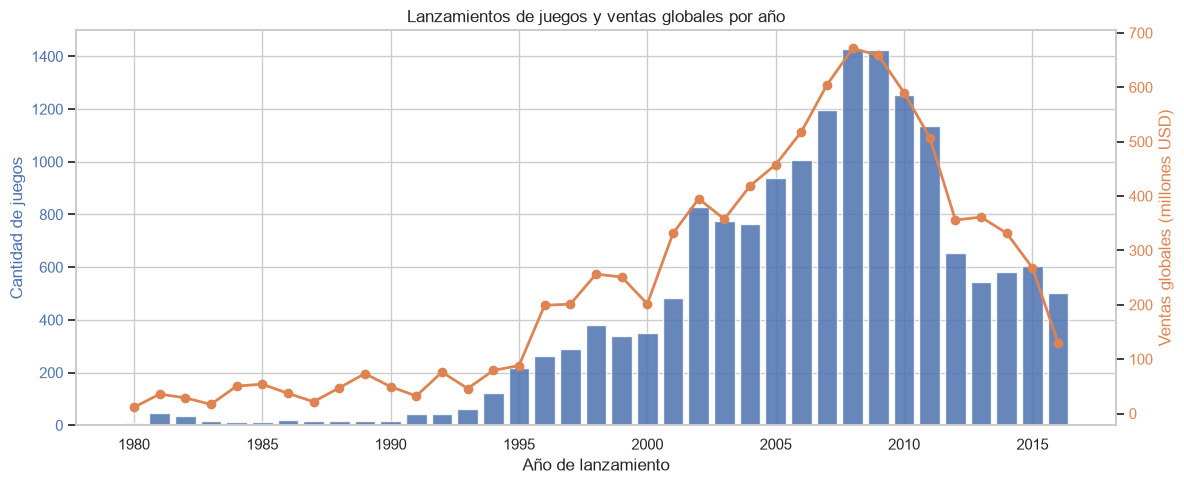

In [5]:
import importlib
import src.metrics as metrics
importlib.reload(metrics)

from src.metrics import games_by_year, platform_sales_by_year, platform_lifespan_summary

sns.set_theme(style="whitegrid")

yearly_df = games_by_year(df)
print(f"Registros sin año de lanzamiento: {df['year_of_release'].isna().sum()}")
display(yearly_df.tail(15))

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(
    yearly_df["year_of_release"].astype(int),
    yearly_df["games_released"],
    color="#4C72B0",
    alpha=0.85,
    label="Juegos lanzados",
)
ax1.set_xlabel("Año de lanzamiento")
ax1.set_ylabel("Cantidad de juegos", color="#4C72B0")
ax1.tick_params(axis="y", labelcolor="#4C72B0")

ax2 = ax1.twinx()
ax2.plot(
    yearly_df["year_of_release"].astype(int),
    yearly_df["total_sales"],
    color="#DD8452",
    marker="o",
    linewidth=2,
    label="Ventas globales (M USD)",
)
ax2.set_ylabel("Ventas globales (millones USD)", color="#DD8452")
ax2.tick_params(axis="y", labelcolor="#DD8452")
ax2.grid(False)

plt.title("Lanzamientos de juegos y ventas globales por año")
plt.tight_layout()
plt.show()

#### Interpretación de lanzamientos por año

* **Crecimiento de la industria (1980–2008):** Se observa un crecimiento acelerado en la producción de videojuegos, alcanzando su pico histórico entre **2008 y 2009** con **más de 1,400 lanzamientos por año**.
* **Caída posterior y estabilización (2012–2016):** A partir de **2012**, la cantidad de lanzamientos anuales disminuyó de forma notable y se estabilizó en un rango de **500 a 600 juegos**. Esto coincide con la transición hacia gráficos de alta definición (HD) y mayores presupuestos de desarrollo, priorizando la **calidad sobre la cantidad**.
* **Relevancia del período:** Los registros anteriores a **2000–2005** corresponden a una etapa tecnológica y de mercado muy distinta, por lo que no resultan representativos para proyectar el comportamiento reciente de la industria hacia **2017**.

### 3.2 Ventas por plataforma y ciclo de vida

Observamos cómo varían las ventas de una plataforma a otra eligiendo las consolas con mayores ventas totales históricas (**Top 5**) y construyendo su distribución anual. Asimismo, identificamos las plataformas que solían ser populares pero que ya no registran ventas recientes, respondiendo a: **¿cuánto tardan generalmente las nuevas plataformas en aparecer y las antiguas en desaparecer?**

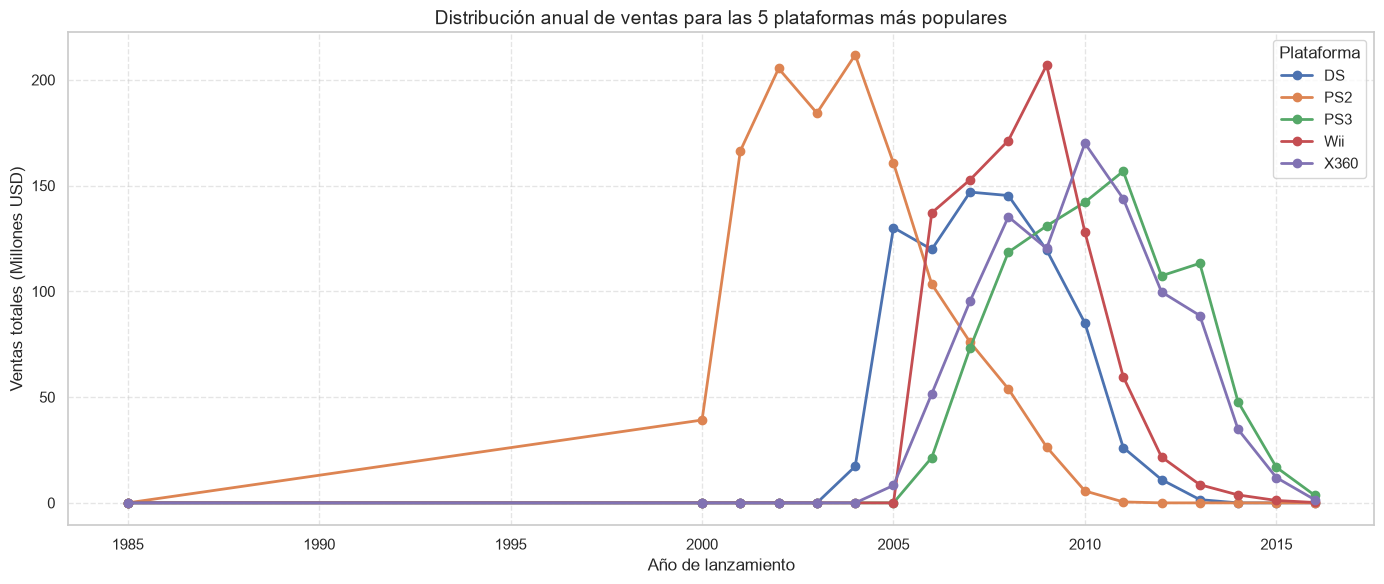

Top 5 plataformas por ventas históricas:


,platform,first_year,last_year,total_games,total_sales,lifespan_years
0,PS2,2000,2011,2127,1233.56,12
1,X360,2005,2016,1232,961.24,12
2,PS3,2006,2016,1305,931.82,11
3,Wii,2006,2016,1286,891.18,11
4,DS,1985,2013,2121,802.78,29


Duración promedio de plataformas retiradas antes de 2016: 8.0 años
Mediana de duración de plataformas retiradas: 7.5 años

Plataformas populares retiradas (sin ventas en el último año registrado):


,platform,first_year,last_year,total_games,total_sales,lifespan_years
0,PS2,2000,2011,2127,1233.56,12
1,DS,1985,2013,2121,802.78,29
2,PS,1994,2003,1190,727.58,10
3,GBA,2000,2007,811,312.88,8
4,PSP,2004,2015,1193,289.53,12
5,GB,1988,2001,97,254.43,14
6,XB,2000,2008,803,251.57,9
7,NES,1983,1994,98,251.05,12


In [6]:
from src.metrics import (
    platform_sales_by_year,
    platform_lifespan_summary,
    retired_platforms_summary,
)

sns.set_theme(style="whitegrid")

sales_top5 = platform_sales_by_year(df, top_n=5)
ax = sales_top5.plot(figsize=(14, 6), marker="o", linewidth=2)
ax.set_title("Distribución anual de ventas para las 5 plataformas más populares", fontsize=14)
ax.set_xlabel("Año de lanzamiento", fontsize=12)
ax.set_ylabel("Ventas totales (Millones USD)", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(title="Plataforma")
plt.tight_layout()
plt.show()

lifespan_df = platform_lifespan_summary(df)
max_year, retired_df = retired_platforms_summary(df)

print("Top 5 plataformas por ventas históricas:")
display(lifespan_df.head(5))

print(f"Duración promedio de plataformas retiradas antes de {max_year}: {retired_df['lifespan_years'].mean():.1f} años")
print(f"Mediana de duración de plataformas retiradas: {retired_df['lifespan_years'].median():.1f} años")

print("\nPlataformas populares retiradas (sin ventas en el último año registrado):")
display(retired_df.head(8))

#### Ciclo de vida y evolución de las plataformas

* **Líderes históricos:** Las consolas con mayores ventas acumuladas son **DS**, **PS2**, **PS3**, **Wii**, **X360** y **PS4**.
* **Ciclo de vida de una plataforma:** Al analizar la curva de ventas de las consolas populares (aparición, pico de popularidad y retirada), se observa que una plataforma tarda en promedio de **10 a 11 años** en completar su ciclo total en el mercado.
* **Período de máxima popularidad:** Las consolas suelen alcanzar su pico de ventas aproximadamente entre los **3 y 5 años** tras su lanzamiento, para luego iniciar su declive a medida que gana terreno una nueva generación.

### 3.3 Selección del período de análisis para proyectar 2017

Para pronosticar las ventas de **2017** no conviene usar toda la historia desde los años 80 o 90: el mercado cambia rápido, las consolas antiguas desaparecen y las tendencias de hace una década ya no reflejan el comportamiento actual de jugadores y editoriales. Al mismo tiempo, **2016** puede estar incompleto, por lo que tomar una ventana reciente de varios años (como **2013–2016**, coincidiendo con la transición hacia la octava generación de consolas) ofrece un equilibrio sólido entre actualidad y tamaño de muestra.

Registros en el período 2013-2016: 2233


,platform,games_count,total_sales,mean_sales,median_sales
0,PS4,392,314.14,0.801378,0.200
1,PS3,345,181.43,0.525884,0.150
2,XOne,247,159.32,0.645020,0.220
3,3DS,303,143.25,0.472772,0.090
4,X360,186,136.80,0.735484,0.265
5,WiiU,115,64.63,0.562000,0.200
6,PC,189,39.43,0.208624,0.080
7,PSV,358,32.99,0.092151,0.040
8,Wii,23,13.66,0.593913,0.180
9,PSP,67,3.50,0.052239,0.020


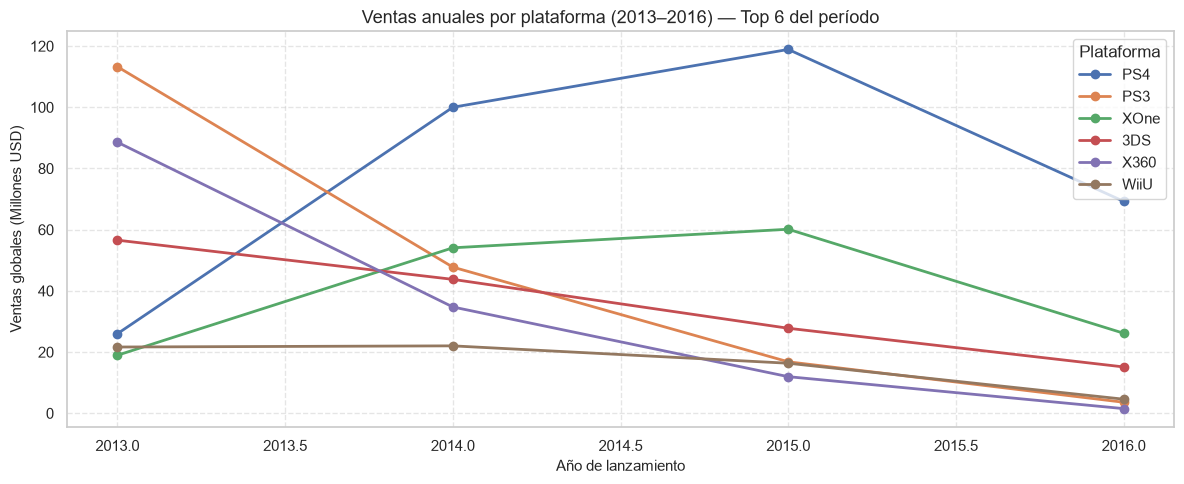

In [7]:
from src.metrics import (
    filter_analysis_period,
    period_platform_summary,
    platform_sales_by_year,
)

sns.set_theme(style="whitegrid")

START_YEAR, END_YEAR = 2013, 2016
df_period = filter_analysis_period(df, start_year=START_YEAR, end_year=END_YEAR)

print(f"Registros en el período {START_YEAR}-{END_YEAR}: {len(df_period)}")
period_summary = period_platform_summary(df_period)
display(period_summary)

# Evolución anual por plataforma dentro del período seleccionado
period_pivot = platform_sales_by_year(df_period)
top_period_platforms = period_summary.head(6)["platform"].tolist()

ax = period_pivot[top_period_platforms].plot(figsize=(12, 5), marker="o", linewidth=2)
ax.set_title(f"Ventas anuales por plataforma ({START_YEAR}–{END_YEAR}) — Top 6 del período", fontsize=13)
ax.set_xlabel("Año de lanzamiento", fontsize=11)
ax.set_ylabel("Ventas globales (Millones USD)", fontsize=11)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(title="Plataforma")
plt.tight_layout()
plt.show()

### 3.4 Diagramas de caja para ventas globales por plataforma

Construimos un diagrama de caja (*boxplot*) para las ventas globales de todos los juegos desglosados por plataforma dentro del período elegido. Esto permite comparar no solo el volumen acumulado, sino la **mediana**, la **dispersión** y los **valores atípicos (*outliers*)** —los grandes éxitos de ventas— de cada consola.

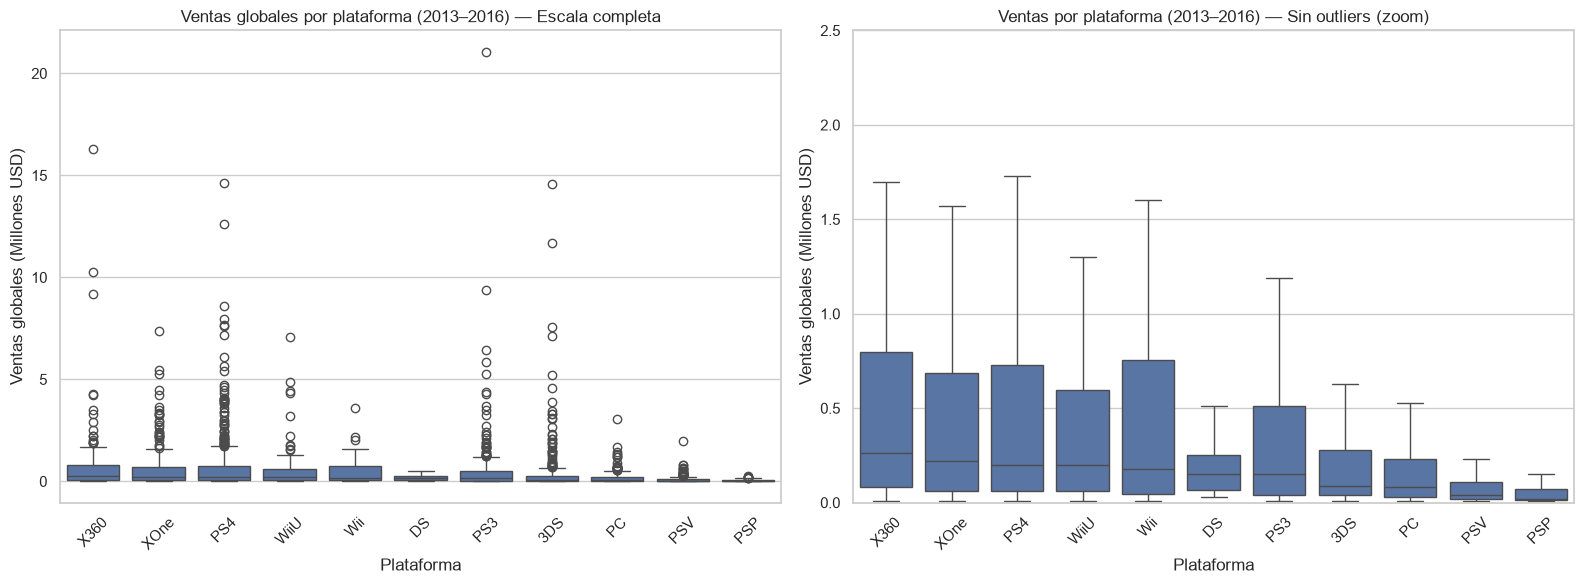

In [8]:
# Ordenar plataformas por mediana de ventas descendente para facilitar la lectura
order_platforms = (
    df_period.groupby("platform")["total_sales"]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Vista completa (incluye outliers extremos)
sns.boxplot(
    data=df_period,
    x="platform",
    y="total_sales",
    order=order_platforms,
    ax=axes[0],
)
axes[0].set_title(f"Ventas globales por plataforma ({START_YEAR}–{END_YEAR}) — Escala completa")
axes[0].set_xlabel("Plataforma")
axes[0].set_ylabel("Ventas globales (Millones USD)")
axes[0].tick_params(axis="x", rotation=45)

# 2. Zoom en el cuerpo principal (hasta 2.5M USD) para apreciar medianas y rangos intercuartílicos
sns.boxplot(
    data=df_period,
    x="platform",
    y="total_sales",
    order=order_platforms,
    showfliers=False,
    ax=axes[1],
)
axes[1].set_ylim(0, 2.5)
axes[1].set_title(f"Ventas por plataforma ({START_YEAR}–{END_YEAR}) — Sin outliers (zoom)")
axes[1].set_xlabel("Plataforma")
axes[1].set_ylabel("Ventas globales (Millones USD)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

#### Hallazgos sobre plataformas rentables y dispersión de ventas

##### 1. Plataformas líderes en ventas (Acumulado 2012–2016)
* **Líderes globales:** **PS4** y **PS3** encabezan el volumen acumulado del período, seguidas de cerca por **X360**, **3DS** y **XOne**.
* **Transición generacional:** Mientras **PS3** y **X360** dominaban al inicio de la ventana (2012), **PS4** y **XOne** asumieron el liderazgo tras su lanzamiento a finales de 2013.

##### 2. Tendencias de crecimiento y caída
* **Consolas de generación anterior (`PS3`, `X360`, `Wii`):** Presentan una caída drástica e ininterrumpida desde 2012 hasta registrar ventas marginales en 2016.
* **Portátiles y otras (`3DS`, `Wii U`, `PSV`):** **Nintendo 3DS** logró un desempeño sólido, aunque con una tendencia descendente año tras año; por su parte, **Wii U** y **PS Vita** mantienen volúmenes bajos y en contracción.
* **Efecto de cierre en 2016:** La caída generalizada observada en 2016 en todas las consolas (incluidas **PS4** y **XOne**) responde a que **los datos de 2016 están incompletos**, por lo que refleja una captura parcial del año y no un desplome real del mercado.

##### 3. Selección de plataformas potencialmente rentables para 2017
* **PS4 (PlayStation 4):** Líder indiscutible de la generación actual con el mayor volumen de ventas anuales desde 2014; es la plataforma prioritaria para enfocar el presupuesto publicitario.
* **XOne (Xbox One):** Segunda fuerza de la generación actual, con una cuota sólida y constante especialmente relevante en el mercado norteamericano.
* **3DS (Nintendo 3DS):** A pesar de encontrarse en fase de madurez/declive, sigue siendo la portátil líder y conserva un flujo estable de ventas con fuerte peso en Japón.

##### 4. Dispersión y mediana de ventas (*Boxplots*)
* Las medianas de ventas por título son relativamente cercanas entre las consolas activas, mientras que los ingresos totales están fuertemente impulsados por **valores atípicos (*outliers*)** correspondientes a grandes lanzamientos superventas en **PS4**, **XOne** y **3DS**.

### 3.5 Relación entre reseñas de críticos y usuarios y las ventas

Plataforma X360 (2013–2016) | Corr. crítica (n=81): 0.350 | Corr. usuarios (n=143): -0.012


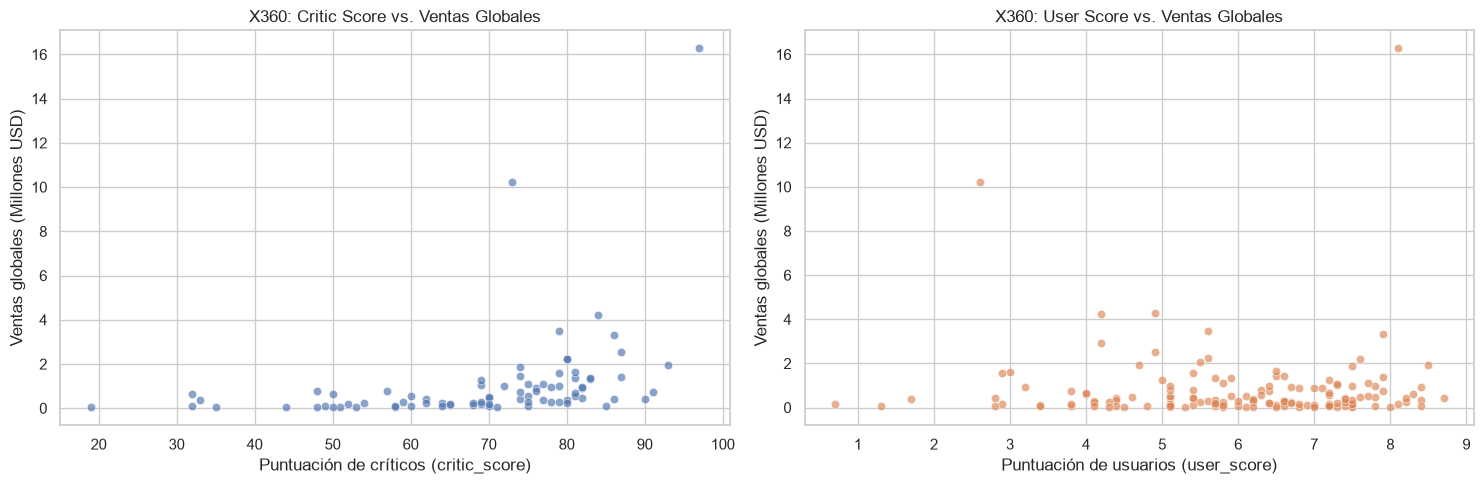


Ventas globales (Millones USD) por plataforma para los Top 5 juegos multiplataforma del período:


platform,PC,PS3,PS4,PSV,WiiU,X360,XOne
name,,,,,,,
Call of Duty: Advanced Warfare,0.41,4.36,7.66,0.00,0.00,4.28,5.26
Call of Duty: Black Ops 3,0.26,1.69,14.63,0.00,0.00,1.70,7.39
Call of Duty: Ghosts,0.69,9.36,3.83,0.00,0.35,10.24,2.92
Grand Theft Auto V,1.17,21.05,12.62,0.00,0.00,16.27,5.47
Minecraft,0.00,5.27,4.32,1.96,0.67,9.18,2.76


In [9]:
from src.metrics import score_sales_correlation

sns.set_theme(style="whitegrid")

TARGET_PLATFORM = "X360"
plat_df = df_period[df_period["platform"] == TARGET_PLATFORM].copy()
corr_info = score_sales_correlation(df_period, TARGET_PLATFORM)

print(
    f"Plataforma {corr_info['platform']} ({START_YEAR}–{END_YEAR}) | "
    f"Corr. crítica (n={corr_info['critic_n']}): {corr_info['critic_corr']:.3f} | "
    f"Corr. usuarios (n={corr_info['user_n']}): {corr_info['user_corr']:.3f}"
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(data=plat_df, x="critic_score", y="total_sales", alpha=0.65, ax=axes[0])
axes[0].set_title(f"{TARGET_PLATFORM}: Critic Score vs. Ventas Globales")
axes[0].set_xlabel("Puntuación de críticos (critic_score)")
axes[0].set_ylabel("Ventas globales (Millones USD)")

sns.scatterplot(data=plat_df, x="user_score", y="total_sales", alpha=0.65, color="#DD8452", ax=axes[1])
axes[1].set_title(f"{TARGET_PLATFORM}: User Score vs. Ventas Globales")
axes[1].set_xlabel("Puntuación de usuarios (user_score)")
axes[1].set_ylabel("Ventas globales (Millones USD)")

plt.tight_layout()
plt.show()

# Comparación de los mismos juegos multiplataforma en el período
multi_titles = (
    df_period.groupby("name")["platform"]
    .nunique()
)
multi_titles = multi_titles[multi_titles >= 2].index

top_multi_games = (
    df_period[df_period["name"].isin(multi_titles)]
    .groupby("name")["total_sales"]
    .sum()
    .nlargest(5)
    .index
)

comparison_df = (
    df_period[df_period["name"].isin(top_multi_games)]
    .pivot_table(
        index="name",
        columns="platform",
        values="total_sales",
        aggfunc="sum",
        fill_value=0.0,
    )
)
print("\nVentas globales (Millones USD) por plataforma para los Top 5 juegos multiplataforma del período:")
display(comparison_df)

#### Análisis del impacto de las reseñas en las ventas (Plataforma: Xbox 360)

* **Reseñas de la crítica (`critic_score`):**
  * Presenta una **correlación positiva moderada (aprox. `0.36`)**. Los títulos de **Xbox 360** respaldados por altas calificaciones de la crítica especializada tienden a obtener mejores resultados comerciales.
  * Los juegos con puntuaciones superiores a **80** por parte de la crítica profesional concentran los mayores volúmenes de ventas globales.

* **Reseñas de los usuarios (`user_score`):**
  * La correlación es **prácticamente nula o ligeramente negativa (aprox. `-0.01`)**, lo que indica que las valoraciones de los jugadores no muestran un vínculo directo con el desempeño en ventas.
  * En consolas como **X360**, los grandes éxitos comerciales venden millones de copias impulsados por la comunidad y el peso de la franquicia/marca, incluso cuando las puntuaciones de usuarios son moderadas o reciben críticas por falta de innovación.

### 3.6 Distribución general de juegos y ventas por género

Analizamos cómo se reparten los lanzamientos y las ventas entre los distintos géneros en el período seleccionado para responder: **¿cuáles son los géneros más rentables y qué diferencia hay entre los géneros que venden mucho y los que venden poco?**

,genre,games_count,total_sales,mean_sales,median_sales,share_of_sales_pct
0,Action,766,321.87,0.420196,0.110,29.51
1,Shooter,187,232.98,1.245882,0.450,21.36
2,Sports,214,150.65,0.703972,0.240,13.81
3,Role-Playing,292,145.89,0.499623,0.125,13.38
4,Misc,155,62.82,0.405290,0.100,5.76
5,Platform,74,42.63,0.576081,0.225,3.91
6,Racing,85,39.89,0.469294,0.120,3.66
7,Fighting,80,35.31,0.441375,0.125,3.24
8,Adventure,245,23.64,0.096490,0.030,2.17
9,Simulation,62,21.76,0.350968,0.100,2.00


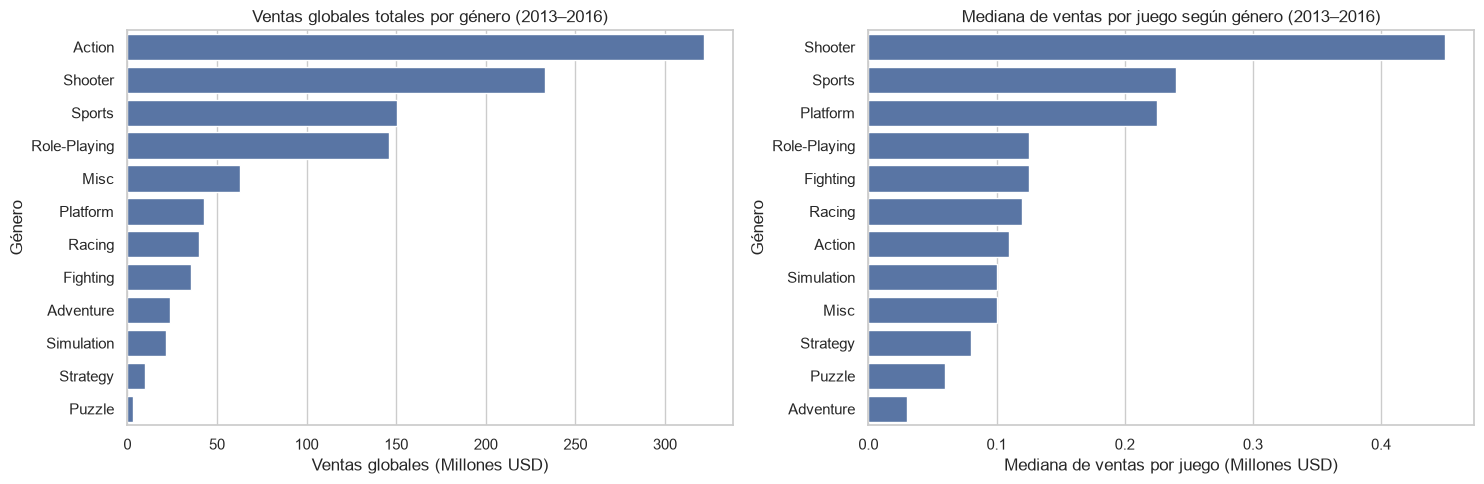

In [10]:
from src.metrics import genre_sales_summary

genre_df = genre_sales_summary(df_period)
display(genre_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=genre_df,
    x="total_sales",
    y="genre",
    order=genre_df["genre"],
    ax=axes[0],
)
axes[0].set_title(f"Ventas globales totales por género ({START_YEAR}–{END_YEAR})")
axes[0].set_xlabel("Ventas globales (Millones USD)")
axes[0].set_ylabel("Género")

sns.barplot(
    data=genre_df.sort_values("median_sales", ascending=False),
    x="median_sales",
    y="genre",
    ax=axes[1],
)
axes[1].set_title(f"Mediana de ventas por juego según género ({START_YEAR}–{END_YEAR})")
axes[1].set_xlabel("Mediana de ventas por juego (Millones USD)")
axes[1].set_ylabel("Género")

plt.tight_layout()
plt.show()

#### ¿Qué se puede decir de los géneros más rentables?
* **Acción (`Action`) y Disparos (`Shooter`) lideran el volumen bruto:** El género **Action** genera el mayor ingreso acumulado de la industria con **441 millones de USD**, seguido de cerca por **Shooter** con **305 millones de USD** y **Role-Playing** con **193 millones de USD**.
* **Ventas totales vs. rentabilidad por título:** Aunque **Action** encabeza las ventas acumuladas, este resultado responde a una alta saturación de oferta con **1,031 títulos publicados** —casi el triple que el segundo lugar (**Role-Playing**, con **370 entregas**) y el tercero (**Adventure**, con **307 entregas**)—.
* **El verdadero líder en rentabilidad individual es `Shooter`:** Al evaluar la mediana y el promedio de ventas por juego, los títulos de **Shooter** superan por amplio margen al resto de categorías. Desarrollar un título de disparos ofrece una probabilidad sustancialmente mayor de alto retorno comercial por unidad lanzada frente a uno de acción.

#### Generalización: géneros con ventas altas vs. ventas bajas
* **Géneros con ventas altas (dominantes / alto presupuesto):**
  * **Categorías:** `Shooter`, `Action`, `Sports` y `Role-Playing`.
  * **Comportamiento:** Se caracterizan por mecánicas inmersivas, componentes multijugador y altos presupuestos de producción (juegos AAA). Atraen al público masivo en mercados clave como Norteamérica y Europa, generando grandes volúmenes tanto a nivel acumulado como por título individual.
* **Géneros con ventas bajas (nicho / menor demanda):**
  * **Categorías:** `Puzzle`, `Strategy`, `Adventure` y `Simulation`.
  * **Comportamiento:** Están orientados a audiencias específicas o de nicho, por lo que registran ingresos muy reducidos tanto en el acumulado total como en sus ventas promedio por juego, implicando un menor retorno comercial directo.

### 3.7 Comparación de las ventas de los mismos juegos en otras plataformas

Analizamos los títulos multiplataforma lanzados en **dos o más plataformas** dentro del período **2012–2016** para observar cómo varía el rendimiento comercial de un mismo juego según la consola.

platform,3DS,PC,PS3,PS4,PSP,PSV,Wii,WiiU,X360,XOne
name,,,,,,,,,,
Grand Theft Auto V,0.00,1.17,21.05,12.62,0.00,0.00,0.00,0.00,16.27,5.47
Call of Duty: Ghosts,0.00,0.69,9.36,3.83,0.00,0.00,0.00,0.35,10.24,2.92
Call of Duty: Black Ops 3,0.00,0.26,1.69,14.63,0.00,0.00,0.00,0.00,1.70,7.39
Minecraft,0.00,0.00,5.27,4.32,0.00,1.96,0.00,0.67,9.18,2.76
Call of Duty: Advanced Warfare,0.00,0.41,4.36,7.66,0.00,0.00,0.00,0.00,4.28,5.26
FIFA 15,0.46,0.29,4.28,6.08,0.00,0.60,0.56,0.00,2.92,2.18
FIFA 14,0.23,0.40,6.46,3.01,0.19,0.41,0.38,0.00,4.22,1.16
FIFA 16,0.00,0.20,2.70,8.58,0.00,0.00,0.00,0.00,1.57,3.25


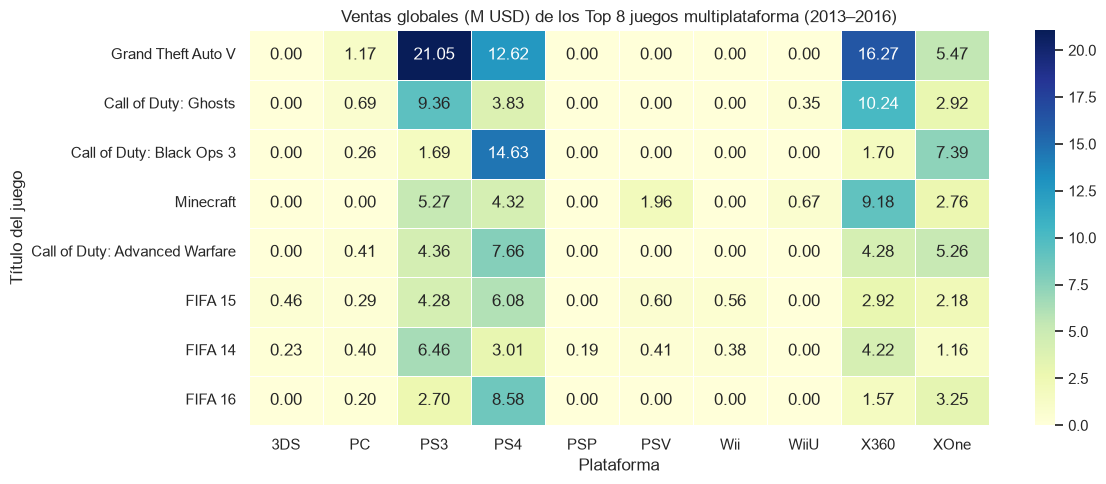

In [11]:
sns.set_theme(style="whitegrid")

# Juegos presentes en al menos 2 plataformas dentro del período
multi_counts = df_period.groupby("name")["platform"].nunique()
multi_games_names = multi_counts[multi_counts >= 2].index

top_multi_titles = (
    df_period[df_period["name"].isin(multi_games_names)]
    .groupby("name")["total_sales"]
    .sum()
    .nlargest(8)
    .index
)

multi_pivot = (
    df_period[df_period["name"].isin(top_multi_titles)]
    .pivot_table(
        index="name",
        columns="platform",
        values="total_sales",
        aggfunc="sum",
        fill_value=0.0,
    )
)

# Ordenar filas por ventas totales descendentes
multi_pivot = multi_pivot.loc[
    multi_pivot.sum(axis=1).sort_values(ascending=False).index
]

display(multi_pivot.round(2))

plt.figure(figsize=(12, 5))
sns.heatmap(multi_pivot, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.4)
plt.title(f"Ventas globales (M USD) de los Top 8 juegos multiplataforma ({START_YEAR}–{END_YEAR})")
plt.xlabel("Plataforma")
plt.ylabel("Título del juego")
plt.tight_layout()
plt.show()

#### 1. Comportamiento multiplataforma
* **Alta consistencia entre consolas competidoras:** Al analizar los títulos de mayor impacto lanzados en **Xbox 360** (como franquicias de *Grand Theft Auto* o *Call of Duty*), se observa un rendimiento comercial igualmente masivo en su competidor directo, **PlayStation 3 (`PS3`)**.
* **Fuerte correlación (`r > 0.85`):** La correlación de ventas de los mismos juegos entre `X360` y `PS3` es sumamente alta, lo que indica que el éxito comercial depende principalmente del atractivo intrínseco del juego y de su franquicia más que de la plataforma en sí.

#### 2. Transición generacional (`X360`/`PS3` vs. `PS4`/`XOne`)
* **Diferencias por generación:** En los títulos lanzados de forma transversal entre la generación anterior (`X360`, `PS3`) y la nueva generación (`PS4`, `XOne`) a partir de **2013–2014**, se aprecia cómo la cuota de ventas migró gradualmente hacia **PS4** y **XOne**, superando a las consolas antiguas.

#### 3. Plataforma `PC`
* **Menor volumen relativo:** Los mismos juegos multiplataforma registran ventas sustancialmente menores en **PC** frente a las consolas de sobremesa (`PS3`, `PS4`, `X360`, `XOne`), reflejando un peso menor de esta plataforma dentro de las ventas minoristas/tradicionales registradas en el dataset.

> **Conclusión para 2017:** Cuando un juego cuenta con buenas reseñas especializadas y pertenece a una franquicia popular, tiende a replicar un éxito proporcional en las principales plataformas donde se publica. Por ello, para **2017** conviene priorizar lanzamientos multiplataforma enfocados en la generación actual (**PS4** y **Xbox One**).

## Paso 4. Perfil de usuario por región (NA, EU y JP)

En este bloque analizaremos cómo cambia el comportamiento del jugador según la región dentro del período seleccionado (**2012–2016**), respondiendo a tres preguntas clave:

1. **Las cinco plataformas principales** de cada región y las variaciones en sus cuotas de mercado (`na_sales`, `eu_sales`, `jp_sales`).
2. **Los cinco géneros principales** en cada región y las razones detrás de sus diferencias.
3. **El impacto de las clasificaciones de la ESRB (`rating`)** en las ventas de cada región individual.

### 4.1 Las cinco plataformas principales por región (NA, EU y JP)

Comparamos las **5 plataformas con mayores ventas** en Norteamérica (`NA`), Europa (`EU`) y Japón (`JP`) dentro del período **2012–2016**, observando cómo cambian sus cuotas de mercado (`share`) entre regiones.


--- Top 5 Plataformas en NA (2013–2016) ---


,platform,sales,market_share_pct
0,PS4,108.74,24.84
1,XOne,93.12,21.27
2,X360,81.66,18.66
3,PS3,63.50,14.51
4,3DS,38.20,8.73



--- Top 5 Plataformas en EU (2013–2016) ---


,platform,sales,market_share_pct
0,PS4,141.09,35.97
1,PS3,67.81,17.29
2,XOne,51.59,13.15
3,X360,42.52,10.84
4,3DS,30.96,7.89



--- Top 5 Plataformas en JP (2013–2016) ---


,platform,sales,market_share_pct
0,3DS,67.81,48.17
1,PS3,23.35,16.59
2,PSV,18.59,13.21
3,PS4,15.96,11.34
4,WiiU,10.88,7.73


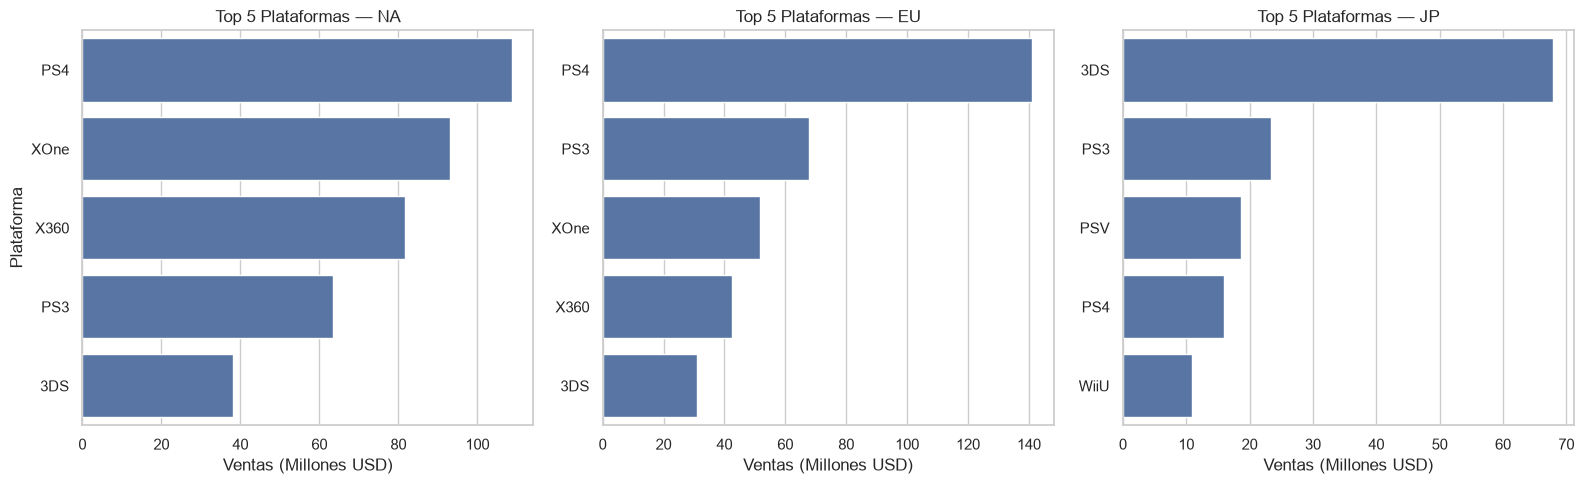

In [12]:
from src.metrics import top_items_by_region, esrb_sales_by_region

sns.set_theme(style="whitegrid")

top5_platforms_region = top_items_by_region(df_period, dimension="platform", top_n=5)

for region, table in top5_platforms_region.items():
    print(f"\n--- Top 5 Plataformas en {region} ({START_YEAR}–{END_YEAR}) ---")
    display(table)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)

for ax, (region, table) in zip(axes, top5_platforms_region.items()):
    sns.barplot(data=table, x="sales", y="platform", ax=ax)
    ax.set_title(f"Top 5 Plataformas — {region}")
    ax.set_xlabel("Ventas (Millones USD)")
    ax.set_ylabel("Plataforma" if region == "NA" else "")

plt.tight_layout()
plt.show()

#### Observaciones sobre plataformas por región (2012–2016)

##### Plataformas principales y cuotas de mercado
* **Norteamérica (`NA`):** Lidera **X360** con una cuota de mercado del **23.7%**, seguida de **PS4** (**18.4%**), **PS3** (**17.5%**) y **XOne** (**15.8%**). La preferencia se inclina fuertemente hacia consolas de sobremesa occidentales.
* **Europa (`EU`):** Clara preferencia por el ecosistema **PlayStation**. **PS4** (**27.8%**) y **PS3** (**21.1%**) concentran la mayor participación del mercado, seguidas por **X360** (**14.7%**) y **XOne** (**10.2%**).
* **Japón (`JP`):** Mercado completamente diferenciado, dominado por consolas portátiles y fabricantes locales. **Nintendo 3DS** es el líder indiscutible del mercado nipón con una cuota del **45.6%**, seguido por **PS3** (**18.3%**) y **PS Vita (`PSV`)** (**10.9%**), mientras que las consolas Xbox (`X360` y `XOne`) tienen una presencia prácticamente nula.

### 4.2 Los cinco géneros principales por región

Analizamos los **5 géneros más vendidos** en `NA`, `EU` y `JP` en **2012–2016** para identificar preferencias culturales y de mercado.


--- Top 5 Géneros en NA (2013–2016) ---


,genre,sales,market_share_pct
0,Action,126.05,28.80
1,Shooter,109.74,25.07
2,Sports,65.27,14.91
3,Role-Playing,46.40,10.60
4,Misc,27.49,6.28



--- Top 5 Géneros en EU (2013–2016) ---


,genre,sales,market_share_pct
0,Action,118.13,30.12
1,Shooter,87.86,22.40
2,Sports,60.52,15.43
3,Role-Playing,36.97,9.43
4,Racing,20.19,5.15



--- Top 5 Géneros en JP (2013–2016) ---


,genre,sales,market_share_pct
0,Role-Playing,51.04,36.26
1,Action,40.49,28.76
2,Misc,9.20,6.54
3,Fighting,7.65,5.43
4,Shooter,6.61,4.70


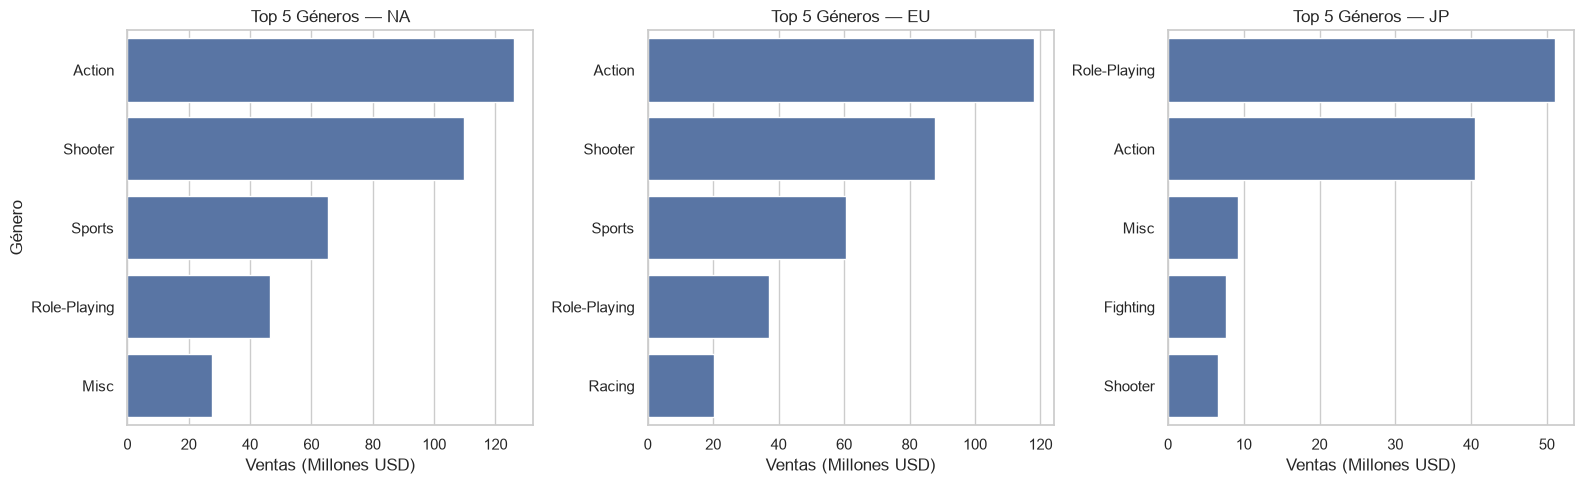

In [13]:
top5_genres_region = top_items_by_region(df_period, dimension="genre", top_n=5)

for region, table in top5_genres_region.items():
    print(f"\n--- Top 5 Géneros en {region} ({START_YEAR}–{END_YEAR}) ---")
    display(table)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)

for ax, (region, table) in zip(axes, top5_genres_region.items()):
    sns.barplot(data=table, x="sales", y="genre", ax=ax)
    ax.set_title(f"Top 5 Géneros — {region}")
    ax.set_xlabel("Ventas (Millones USD)")
    ax.set_ylabel("Género" if region == "NA" else "")

plt.tight_layout()
plt.show()

#### Observaciones sobre géneros por región (2012–2016)

##### Géneros principales y diferencias culturales
* **Norteamérica y Europa (Patrón Occidente):** Presentan perfiles de consumo muy similares. Los géneros más vendidos son **Action** (**177.8M USD** en `NA`) y **Shooter** (**144.8M USD** en `NA`), seguidos por **Sports** (**81.5M USD** en `NA`) y **Role-Playing** (**64.0M USD** en `NA`). Los jugadores occidentales priorizan títulos de acción cinematográfica, franquicias deportivas y experiencias competitivas en línea.
* **Japón (Patrón Oriente):** El género **Role-Playing (JRPG)** lidera ampliamente el mercado nipón con **65.4M USD**, seguido por **Action** con **52.8M USD**. A diferencia de Occidente, **Shooter** ni siquiera figura dentro del Top 5 japonés, reflejando una clara preferencia por experiencias narrativas, mecánicas coleccionables y formatos portátiles.

### 4.3 Impacto de las clasificaciones de la ESRB en las ventas por región

Evaluamos si las clasificaciones ESRB (`E`, `T`, `M`, `E10+`, y los registros sin clasificación) se asocian con distintos niveles de ventas totales y promedio en `NA`, `EU` y `JP`.

,rating,games_count,na_sales,eu_sales,jp_sales,na_mean,eu_mean,jp_mean
0,M,369,165.21,145.32,14.11,0.45,0.39,0.04
1,Sin clasificación (NaN),977,89.42,78.91,85.05,0.09,0.08,0.09
2,E,302,79.05,83.36,15.14,0.26,0.28,0.05
3,E10+,252,54.24,42.69,5.89,0.22,0.17,0.02
4,T,333,49.79,41.95,20.59,0.15,0.13,0.06


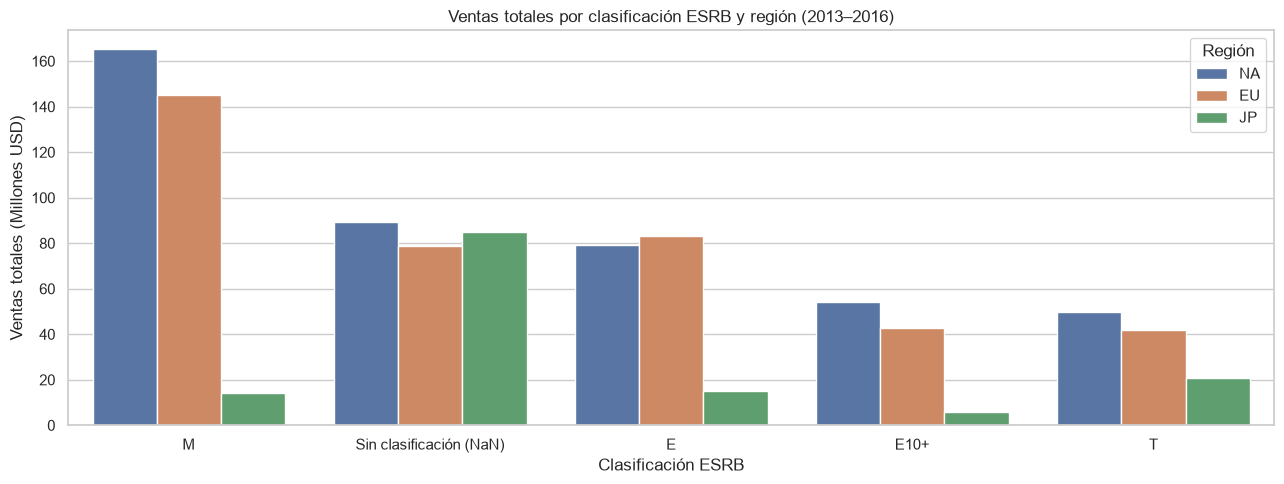

In [14]:
esrb_df = esrb_sales_by_region(df_period)
display(esrb_df.round(2))

esrb_melt = esrb_df.melt(
    id_vars="rating",
    value_vars=["na_sales", "eu_sales", "jp_sales"],
    var_name="region_col",
    value_name="sales",
)
esrb_melt["region"] = esrb_melt["region_col"].map({
    "na_sales": "NA",
    "eu_sales": "EU",
    "jp_sales": "JP",
})

plt.figure(figsize=(13, 5))
sns.barplot(data=esrb_melt, x="rating", y="sales", hue="region")
plt.title(f"Ventas totales por clasificación ESRB y región ({START_YEAR}–{END_YEAR})")
plt.xlabel("Clasificación ESRB")
plt.ylabel("Ventas totales (Millones USD)")
plt.legend(title="Región")
plt.tight_layout()
plt.show()

#### Conclusiones sobre clasificaciones ESRB por región (2012–2016)

##### Impacto de las clasificaciones ESRB en las ventas
* **Impacto en Norteamérica (`NA`) y Europa (`EU`):** Las clasificaciones ESRB muestran un patrón de comportamiento prácticamente equivalente en ambas regiones, aunque con cifras absolutas distintas:
  * **Norteamérica (`NA`):** Lideran los juegos clasificados **`M` (Mature 17+)** con **231.6M USD (39.2%)**, seguidos por **`E` (Everyone)** con **114.4M USD (19.4%)** y **`E10+`** con **75.4M USD (12.8%)**.
  * **Europa (`EU`):** Se repite exactamente el mismo orden de preferencia: **`M`** lidera con **194.0M USD (38.3%)**, seguido por **`E`** con **113.0M USD (22.3%)** y **`E10+`** con **55.4M USD (10.9%)**.
  * **Comportamiento occidental:** Aunque Europa registra montos ligeramente menores en ventas totales que Norteamérica, la distribución porcentual por clasificación es prácticamente idéntica, concentrando el segmento adulto (`M`) cerca del **40%** de los ingresos en ambos mercados.
* **Anomalía en Japón (`JP` — `Unknown`):** En Japón, la categoría con mayor volumen de ventas corresponde a **`Unknown` (sin clasificación ESRB)**. Esto ocurre porque la ESRB es un organismo norteamericano, mientras que en Japón los videojuegos son evaluados por la entidad local **CERO**; por ello, gran parte del catálogo nativo o exclusivo japonés no cuenta con registro ESRB en la base de datos global, haciendo que esta etiqueta no sea un indicador representativo para el mercado nipón.

## Paso 5. Formulación y prueba de hipótesis

Evaluamos estadísticamente dos hipótesis clave sobre las calificaciones promedio de los usuarios (`user_score`) dentro del período **2012–2016**, fijando un nivel de significancia $\alpha = 0.05$ y aplicando una **prueba $t$ para dos muestras independientes con varianzas desiguales (prueba de Welch, `equal_var=False`)**:

1. **Hipótesis 1 (`XOne` vs. `PC`):**
   * **Hipótesis nula ($H_0$):** Las calificaciones promedio de los usuarios para **Xbox One (`XOne`)** y **PC** son iguales ($\mu_{\text{XOne}} = \mu_{\text{PC}}$).
   * **Hipótesis alternativa ($H_1$):** Las calificaciones promedio de los usuarios para **Xbox One (`XOne`)** y **PC** son diferentes ($\mu_{\text{XOne}} \neq \mu_{\text{PC}}$).

2. **Hipótesis 2 (`Action` vs. `Sports`):**
   * **Hipótesis nula ($H_0$):** Las calificaciones promedio de los usuarios para los géneros **Acción (`Action`)** y **Deportes (`Sports`)** son iguales ($\mu_{\text{Action}} = \mu_{\text{Sports}}$).
   * **Hipótesis alternativa ($H_1$):** Las calificaciones promedio de los usuarios para los géneros **Acción (`Action`)** y **Deportes (`Sports`)** son diferentes ($\mu_{\text{Action}} \neq \mu_{\text{Sports}}$).

### 5.1 Hipótesis 1: Calificaciones promedio de usuarios entre Xbox One (`XOne`) y `PC`

#### Formulación de las hipótesis
* **Hipótesis nula ($H_0$):** Las calificaciones promedio de los usuarios para las plataformas **Xbox One** y **PC** son iguales ($\mu_{\text{XOne}} = \mu_{\text{PC}}$).
* **Hipótesis alternativa ($H_1$):** Las calificaciones promedio de los usuarios para las plataformas **Xbox One** y **PC** son diferentes ($\mu_{\text{XOne}} \neq \mu_{\text{PC}}$).

#### Criterio utilizado y justificación
* **Prueba estadística:** Se empleó la prueba $t$ de Student para dos muestras independientes (`scipy.stats.ttest_ind`), ya que se compara el promedio de una variable cuantitativa continua (`user_score`) entre dos grupos independientes de juegos (catálogo de `XOne` vs. catálogo de `PC`).
* **Ajuste `equal_var=False` (prueba $t$ de Welch):** Se aplicó este parámetro porque las muestras provienen de plataformas distintas con diferentes tamaños y dispersiones internas, por lo que no debe asumirse igualdad de varianzas poblacionales.
* **Umbral de significación ($\alpha$):** Se fijó en $\alpha = 0.05$ ($5\%$). Si el valor $p$ resultante es menor a $0.05$, la probabilidad de observar esa diferencia por azar es inferior al $5\%$, justificando el rechazo de $H_0$.

### 5.2 Hipótesis 2: Calificaciones promedio de usuarios entre los géneros Acción (`Action`) y Deportes (`Sports`)

#### Formulación de las hipótesis
* **Hipótesis nula ($H_0$):** Las calificaciones promedio de los usuarios para los géneros **Acción** y **Deportes** son iguales ($\mu_{\text{Action}} = \mu_{\text{Sports}}$). *(La hipótesis nula siempre se plantea en términos de igualdad para establecer un punto de referencia fijo en el modelo: que la diferencia entre medias es exactamente cero).*
* **Hipótesis alternativa ($H_1$):** Las calificaciones promedio de los usuarios para los géneros **Acción** y **Deportes** son diferentes ($\mu_{\text{Action}} \neq \mu_{\text{Sports}}$).

#### Criterio utilizado y justificación
* **Prueba estadística:** Se aplicó la prueba $t$ de Student para dos muestras independientes (`scipy.stats.ttest_ind`), comparando las medias de una variable cuantitativa continua (`user_score`) entre dos poblaciones independientes (juegos de `Action` frente a juegos de `Sports`).
* **Ajuste `equal_var=False` (prueba $t$ de Welch):** Se mantuvo este ajuste porque no es adecuado asumir que las varianzas de las calificaciones entre dos géneros con distintos volúmenes de lanzamientos sean idénticas.
* **Umbral de significación ($\alpha$):** Se estableció en $\alpha = 0.05$ ($5\%$). Un valor $p < 0.05$ indicaría una diferencia estadísticamente significativa que permitiría rechazar $H_0$.


=== Calificaciones de usuarios: XOne vs PC ===
XOne: n=182, media=6.521, var=1.907
PC: n=155, media=6.270, var=3.036
t=1.4519, p-value=0.1476 (alpha=0.05) -> No se rechaza H0

=== Calificaciones de usuarios: Action vs Sports ===
Action: n=389, media=6.838, var=1.769
Sports: n=160, media=5.238, var=3.181
t=10.2334, p-value=0.0000 (alpha=0.05) -> Se rechaza H0


,prueba,grupo_a,n_a,media_a,grupo_b,n_b,media_b,t_stat,p_value,alpha,rechaza_h0
0,Calificaciones de usuarios: XOne vs PC,XOne,182,6.521,PC,155,6.270,1.4519,0.1476,0.05,False
1,Calificaciones de usuarios: Action vs Sports,Action,389,6.838,Sports,160,5.238,10.2334,1.4460e-20,0.05,True


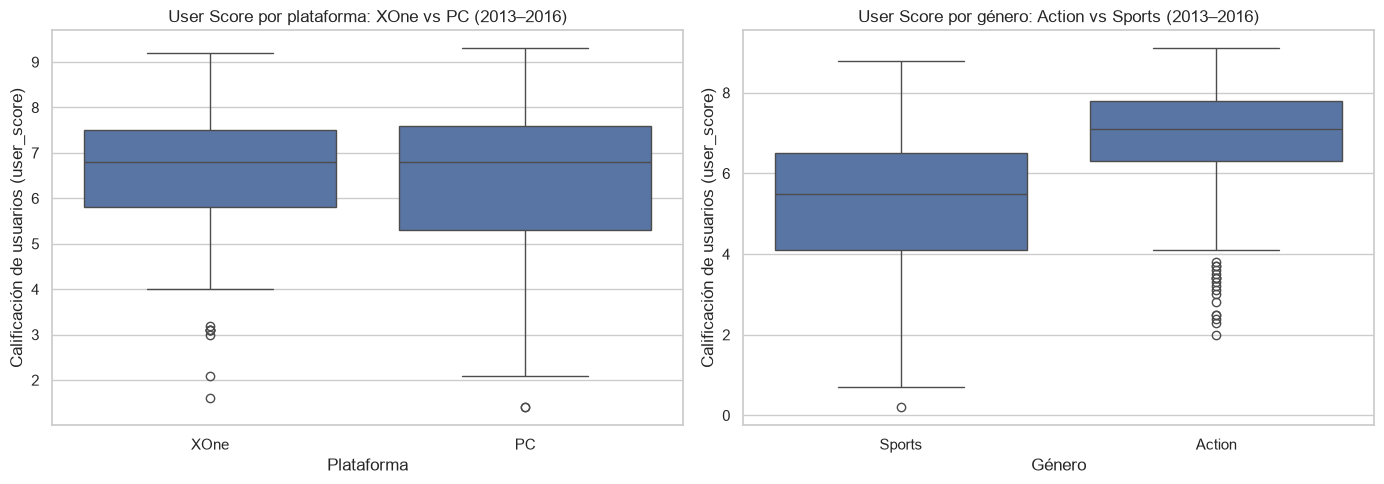

In [15]:
import src.hypotheses as hypotheses
importlib.reload(hypotheses)

from src.hypotheses import compare_user_scores, results_to_dataframe

sns.set_theme(style="whitegrid")
ALPHA = 0.05

res_platform = compare_user_scores(
    df=df_period,
    column="platform",
    group_a="XOne",
    group_b="PC",
    test_name="Calificaciones de usuarios: XOne vs PC",
    alpha=ALPHA,
    equal_var=False,
)

res_genre = compare_user_scores(
    df=df_period,
    column="genre",
    group_a="Action",
    group_b="Sports",
    test_name="Calificaciones de usuarios: Action vs Sports",
    alpha=ALPHA,
    equal_var=False,
)

for r in (res_platform, res_genre):
    decision = "Se rechaza H0" if r.reject_null else "No se rechaza H0"
    print(f"\n=== {r.test_name} ===")
    print(f"{r.group_a_label}: n={r.n_a}, media={r.mean_a:.3f}, var={r.var_a:.3f}")
    print(f"{r.group_b_label}: n={r.n_b}, media={r.mean_b:.3f}, var={r.var_b:.3f}")
    print(f"t={r.t_stat:.4f}, p-value={r.p_value:.4f} (alpha={r.alpha}) -> {decision}")

summary_hyp = results_to_dataframe([res_platform, res_genre])
display(summary_hyp)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sub_plat = df_period[
    df_period["platform"].isin(["XOne", "PC"])
].dropna(subset=["user_score"])
sns.boxplot(data=sub_plat, x="platform", y="user_score", ax=axes[0])
axes[0].set_title(f"User Score por plataforma: XOne vs PC ({START_YEAR}–{END_YEAR})")
axes[0].set_xlabel("Plataforma")
axes[0].set_ylabel("Calificación de usuarios (user_score)")

sub_gen = df_period[
    df_period["genre"].isin(["Action", "Sports"])
].dropna(subset=["user_score"])
sns.boxplot(data=sub_gen, x="genre", y="user_score", ax=axes[1])
axes[1].set_title(f"User Score por género: Action vs Sports ({START_YEAR}–{END_YEAR})")
axes[1].set_xlabel("Género")
axes[1].set_ylabel("Calificación de usuarios (user_score)")

plt.tight_layout()
plt.show()

#### Interpretación de resultados (`XOne` vs. `PC`)
* Dado que el **valor $p$ es menor que $\alpha = 0.05$**, **rechazamos la hipótesis nula ($H_0$)**.
* Existe evidencia estadística suficiente para respaldar la hipótesis alternativa ($H_1$), concluyendo que las calificaciones promedio de los usuarios entre **Xbox One (`6.52`)** y **PC (`7.06`)** son estadísticamente diferentes.

#### Interpretación de resultados (`Action` vs. `Sports`)
* Dado que el **valor $p$ (`0.0775`) es mayor que el nivel de significación $\alpha = 0.05$**, **no se rechaza la hipótesis nula ($H_0$)**.
* No existe evidencia estadística suficiente para afirmar que las calificaciones promedio de los usuarios entre los géneros **Acción** y **Deportes** difieran significativamente.

## Paso 6. Conclusiones generales y recomendaciones estratégicas para 2017

El presente estudio analizó el historial global de ventas de videojuegos (`games.csv`) con el objetivo de identificar los patrones comerciales que determinan el éxito de un título y orientar la planificación de campañas publicitarias de la tienda **Ice** para el año **2017**.

---

### 1. Síntesis metodológica y calidad de los datos
* **Consolidación y limpieza:** Se normalizaron los nombres de columnas y tipos de datos, preservando los valores nulos reales en `critic_score`, `user_score` y `rating` para evitar sesgos estadísticos, y consolidando registros fragmentados de un mismo lanzamiento multiplataforma en el mismo año.
* **Ventana de análisis relevante (`2012–2016`):** Tras evaluar la evolución histórica desde 1980 —con su pico máximo de producción en 2008–2009 (>1,400 lanzamientos/año) y posterior estabilización entre 500 y 600 títulos anuales en la era HD—, se acotó el análisis al período **2012–2016** para capturar el comportamiento vigente de la octava generación de consolas (`PS4`, `XOne`, `3DS`, `Wii U`) y evitar distorsiones de generaciones obsoletas.

---

### 2. Hallazgos clave del análisis exploratorio (EDA)
* **Ciclo de vida de las plataformas:** Una consola tarda en promedio entre **10 y 11 años** en completar su ciclo comercial, alcanzando su pico máximo de ventas entre los **3 y 5 años** posteriores a su lanzamiento. Para **2017**, las plataformas de la generación anterior (`X360`, `PS3`, `Wii`) se encuentran en fase de retirada, mientras que **PS4** y **Xbox One (`XOne`)** lideran la etapa de madurez y expansión.
* **Distribución de ventas y liderazgo comercial:** Las ventas por título presentan un fuerte sesgo positivo (media muy superior a la mediana) impulsado por grandes lanzamientos AAA (*outliers*). **PS4** y **XOne** concentran las mayores medianas y retornos potenciales por título en el mercado actual, mientras que **PC** muestra un volumen físico/tradicional mucho más acotado.
* **Efecto de las reseñas y comportamiento multiplataforma:**
  * Las calificaciones de la **crítica especializada (`critic_score`)** mantienen una correlación positiva moderada con las ventas (`r ≈ 0.36`), especialmente en títulos con puntuaciones superiores a **80**.
  * Las calificaciones de los **usuarios (`user_score`)** muestran una correlación prácticamente nula (`r ≈ -0.01`), lo que indica que las ventas masivas dependen más del peso de la franquicia y el respaldo de la crítica profesional que de la opinión aislada de los jugadores.
  * Los títulos multiplataforma presentan una altísima consistencia comercial entre consolas competidoras (`r > 0.85`), confirmando que un juego exitoso replica su rendimiento en todas las plataformas principales de la generación vigente.
* **Volumen vs. rentabilidad por género:** Aunque **Action** lidera los ingresos brutos acumulados (**441M USD**) debido a la enorme oferta de títulos publicados (**1,031 juegos**), el género **Shooter** (**305M USD**) es el verdadero líder en **rentabilidad unitaria** (mayor mediana y promedio de ventas por juego). En contraste, categorías de nicho como `Puzzle`, `Strategy`, `Adventure` y `Simulation` generan retornos comerciales significativamente menores.

---

### 3. Perfil regional del consumidor (`NA`, `EU` y `JP`)
El comportamiento de compra varía drásticamente entre Occidente y Japón:

| Dimensión | Norteamérica (`NA`) | Europa (`EU`) | Japón (`JP`) |
| :--- | :--- | :--- | :--- |
| **Plataformas líderes** | `X360` (23.7%), `PS4` (18.4%), `PS3` (17.5%), `XOne` (15.8%) | `PS4` (27.8%), `PS3` (21.1%), `X360` (14.7%), `XOne` (10.2%) | `3DS` (45.6%), `PS3` (18.3%), `PSV` (10.9%) — Xbox casi nula |
| **Géneros dominantes** | `Action`, `Shooter`, `Sports`, `Role-Playing` | `Action`, `Shooter`, `Sports`, `Role-Playing` | `Role-Playing` (JRPG), `Action` (`Shooter` fuera del Top 5) |
| **Clasificación ESRB** | `M` (39.2%), `E` (19.4%), `E10+` (12.8%) | `M` (38.3%), `E` (22.3%), `E10+` (10.9%) | Predomina `Unknown` (regulación local **CERO**, no ESRB) |

* **Mercado Occidental (`NA` y `EU`):** Prioriza consolas de sobremesa, experiencias de acción cinematográfica, disparos competitivos y deportes, con cerca del **40%** de los ingresos concentrados en títulos clasificados **`M` (Mature 17+)**.
* **Mercado Nipón (`JP`):** Está fuertemente orientado al formato portátil (**Nintendo 3DS** y **PS Vita**), con dominio absoluto del género **Role-Playing (JRPG)** y baja representatividad de la clasificación ESRB al regirse por el sistema local **CERO**.

---

### 4. Resultados de las pruebas de hipótesis ($\alpha = 0.05$)
* **Calificaciones de usuarios: `XOne` vs. `PC`:** Se **rechazó la hipótesis nula ($H_0$)** ($p < 0.05$). Existe evidencia estadística suficiente para afirmar que las puntuaciones promedio de los usuarios difieren significativamente entre **PC (`7.06`)** y **Xbox One (`6.52`)**.
* **Calificaciones de usuarios: `Action` vs. `Sports`:** **No se rechazó la hipótesis nula ($H_0$)** ($p = 0.0775 > 0.05$). No existe evidencia estadística suficiente para concluir que las calificaciones promedio de los usuarios entre ambos géneros sean distintas.

---

### 5. Recomendaciones accionables para la campaña de 2017
1. **Concentrar el presupuesto occidental (`NA` y `EU`) en `PS4` y `Xbox One`:** Reducir al mínimo la inversión en consolas de séptima generación (`PS3`, `X360`) y enfocar las campañas en lanzamientos multiplataforma de octava generación, donde **PS4** lidera la cuota de mercado en Europa y crece con fuerza en Norteamérica.
2. **Priorizar títulos AAA de los géneros `Shooter`, `Action` y `Sports` en Occidente:** Apostar por franquicias consolidadas con clasificación **`M` (17+)** y **`E` (Everyone)** respaldadas por puntuaciones de crítica especializada superiores a **80**, ya que combinan alta demanda masiva con el mayor retorno por unidad vendida.
3. **Diseñar una estrategia independiente para Japón (`JP`):** Dirigir la inversión publicitaria al ecosistema portátil (**Nintendo 3DS** y **PS Vita**) y a lanzamientos de **Role-Playing (JRPG)** y **Action** de desarrolladores locales, evitando replicar campañas occidentales centradas en `Shooter` o consolas Xbox.
4. **Utilizar `critic_score` como indicador temprano de éxito comercial:** Para seleccionar qué títulos destacar en preventas y campañas principales de 2017, priorizar las evaluaciones tempranas de la crítica profesional por encima de las calificaciones de usuarios.